# Islamabad plot listings (Zameen.com scrape)

Source: https://www.kaggle.com/datasets/saroshkhann/islamabad-plots-prices-dataset

Raw scraped listings of plots for sale in Islamabad. The plan was price per marla by location. These are asking prices from listings, not what anything actually sold for, so everything below is about what sellers are asking.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_colwidth', 70)
pd.set_option('display.width', 200)

Path('charts').mkdir(exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})
group_colors = {'Lettered sector': '#2a78d6', 'DHA Defence': '#eb6834', 'Other society': '#1baf7a'}

## Loading and first look

In [2]:
raw = pd.read_csv('islamabad_raw.csv')
print(raw.shape)
raw.head(8)

(18700, 6)


,title,price,location,area,link,page_scraped
0,CORNER CUTTING AREA PLOT,2.1 Crore,"E-12/1, E-12",4.4 Marla,https://www.zameen.com/Property/e_12_e-12_1_corner_cutting_area_pl...,1
1,CDA Sector I-12 Top Location Plot Available For Sale,2.25 Crore,"I-12/1, I-12",8 Marla,https://www.zameen.com/Property/i_12_i-12_1_cda_sector_i-12_top_lo...,1
2,Margalla Enclave 3rd Ballot 10 Marla Plot Available On Easy Instal...,4.9 Crore,"Margalla Enclave, Margalla Avenue",10 Marla,https://www.zameen.com/Property/margalla_avenue_margalla_enclave_m...,1
3,plot for sale,32 Lakh,"PECHS - Block M, PECHS",5 Marla,https://www.zameen.com/Property/pechs_pechs_-_block_m_plot_for_sal...,1
4,Stunning Residential Plot Is Available For Sale In AWT - Block G,32 Lakh,"AWT - Block G, AWT",10 Marla,https://www.zameen.com/Property/awt_awt_-_block_g_stunning_residen...,1
5,5 Marla C15 Plot File,32 Lakh,"C-15, Islamabad",5 Marla,https://www.zameen.com/Property/islamabad_c-15_5_marla_c15_plot_fi...,1
6,Park Enclave 1 Islamabad Prime Main Boulevard Pair of Plots Availa...,5.6 Crore,"Park Enclave 1, Park Enclave",1 Kanal,https://www.zameen.com/Property/park_enclave_park_enclave_1_park_e...,1
7,1 KANAL CORNER Plot Available For Sale In D-12/3,15.25 Crore,"D-12/3, D-12",1 Kanal,https://www.zameen.com/Property/d_12_d-12_3_1_kanal_corner_plot_av...,1


In [3]:
raw.info()
print()
print('missing values per column:')
print(raw.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 18700 entries, 0 to 18699
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   title         18700 non-null  str  
 1   price         18700 non-null  str  
 2   location      18700 non-null  str  
 3   area          18700 non-null  str  
 4   link          18700 non-null  str  
 5   page_scraped  18700 non-null  int64
dtypes: int64(1), str(5)
memory usage: 876.7 KB

missing values per column:
title           0
price           0
location        0
area            0
link            0
page_scraped    0
dtype: int64


No missing values, six columns, everything except `page_scraped` is text. No date column, so no time trends are possible. Check the formats of price and area before parsing.

In [4]:
# replace the numbers with N to see what text patterns exist
print(raw['price'].str.replace(r'[\d.,]+', 'N', regex=True).value_counts())
print()
print(raw['area'].str.replace(r'[\d.,]+', 'N', regex=True).value_counts())
print()
print('distinct locations:', raw['location'].nunique())
print('all links on zameen.com:', raw['link'].str.startswith('https://www.zameen.com/Property/').all())

price
N Crore    13464
N Lakh      5236
Name: count, dtype: int64

area
N Marla    9724
N Kanal    8976
Name: count, dtype: int64

distinct locations: 22
all links on zameen.com: True


Only two price units (Lakh, Crore) and two area units (Marla, Kanal). No Arab, no square yards, no ranges. But only 22 distinct locations in 18,700 rows is suspicious. Look at duplicates.

In [5]:
print('fully identical rows:', raw.duplicated().sum())
print('rows identical ignoring page_scraped:', raw.drop(columns='page_scraped').duplicated().sum())
print('distinct links:', raw['link'].nunique())
print('distinct page_scraped values:', raw['page_scraped'].nunique(), '(', raw['page_scraped'].min(), 'to', raw['page_scraped'].max(), ')')
print()
print('rows per page:', raw.groupby('page_scraped').size().unique())
print('times each link appears:', raw.groupby('link').size().unique())
print('distinct sets of links across pages:', raw.groupby('page_scraped')['link'].apply(frozenset).nunique())

fully identical rows: 0
rows identical ignoring page_scraped: 18675
distinct links: 25
distinct page_scraped values: 748 ( 1 to 748 )

rows per page: [25]
times each link appears: [748]
distinct sets of links across pages: 1


This is the main thing about the dataset. There are only 25 distinct listings. The scraper recorded the same 25 listings on every one of 748 "pages" (25 x 748 = 18,700), so the page number is the only thing that differs between rows. It looks like the pagination did not actually advance and page 1 was saved 748 times. I can't confirm the cause from the file, but the effect is certain: 18,675 of the 18,700 rows are repeats.

So this is a 25-listing sample, not an 18,700-listing market dataset. Everything from here on is on those 25, and it should be read as a small snapshot.

## Cleaning

In [6]:
# 1. drop the repeated scrapes: one row per listing URL
df = raw.drop_duplicates(subset='link').drop(columns='page_scraped').reset_index(drop=True)
print(len(raw), '->', len(df), 'rows')

# listing id is the first number block in the URL
df['listing_id'] = df['link'].str.extract(r'-(\d+)-\d+-\d+\.html$')[0].astype(int)
print('listing ids unique:', df['listing_id'].is_unique)

18700 -> 25 rows
listing ids unique: True


`page_scraped` is dropped because it carries no information once the repeats are gone.

In [7]:
# 2. price text -> rupees. 1 lakh = 100,000 and 1 crore = 10,000,000
unit_pkr = {'lakh': 1e5, 'crore': 1e7, 'arab': 1e9}
p = df['price'].str.extract(r'^([\d.,]+)\s*(\w+)$')
df['price_pkr'] = (p[0].str.replace(',', '').astype(float) * p[1].str.lower().map(unit_pkr)).round().astype('int64')
df['price_crore'] = df['price_pkr'] / 1e7

# 3. area text -> marla. 1 kanal = 20 marla
unit_marla = {'marla': 1, 'kanal': 20}
a = df['area'].str.extract(r'^([\d.,]+)\s*(\w+)$')
df['area_marla'] = a[0].astype(float) * a[1].str.lower().map(unit_marla)

df['price_per_marla_lakh'] = (df['price_pkr'] / df['area_marla'] / 1e5).round(2)
print('unparsed prices:', df['price_pkr'].isna().sum(), ' unparsed areas:', df['area_marla'].isna().sum())
df[['price', 'price_pkr', 'area', 'area_marla', 'price_per_marla_lakh']].head(8)

unparsed prices: 0  unparsed areas: 0


,price,price_pkr,area,area_marla,price_per_marla_lakh
0,2.1 Crore,21000000,4.4 Marla,4.4,47.73
1,2.25 Crore,22500000,8 Marla,8.0,28.12
2,4.9 Crore,49000000,10 Marla,10.0,49.00
3,32 Lakh,3200000,5 Marla,5.0,6.40
4,32 Lakh,3200000,10 Marla,10.0,3.20
5,32 Lakh,3200000,5 Marla,5.0,6.40
6,5.6 Crore,56000000,1 Kanal,20.0,28.00
7,15.25 Crore,152500000,1 Kanal,20.0,76.25


Some titles give plot dimensions in feet (25x50, 30x70 ...). That lets me check which marla Zameen is using, since a marla is 225 sq ft in some conventions and 272.25 in others.

In [8]:
dims = df['title'].str.extract(r'(\d{2})\s*x\s*(\d{2})', flags=re.I).astype(float)
chk = df.loc[dims[0].notna(), ['title', 'area', 'area_marla']].copy()
chk['sq_ft_from_title'] = dims[0] * dims[1]
chk['marla_at_225'] = (chk['sq_ft_from_title'] / 225).round(1)
chk['marla_at_272'] = (chk['sq_ft_from_title'] / 272.25).round(1)
chk

,title,area,area_marla,sq_ft_from_title,marla_at_225,marla_at_272
12,30x70 plot for sale,9.3 Marla,9.3,2100.0,9.3,7.7
13,25x50 Plot For Sale,5 Marla,5.0,1250.0,5.6,4.6
19,Main Double Road 50x90 Faisal Hills B Block Plot For Sale,1 Kanal,20.0,4500.0,20.0,16.5
20,Main Road (100 Ft) 35x70 Plot For Sale in A Block - Gulberg Reside...,10.9 Marla,10.9,2450.0,10.9,9.0
21,Faisal Hills A Block 25x50 Close To Park,5.6 Marla,5.6,1250.0,5.6,4.6
22,B-17 A Block 50x90 2nd Corner,1 Kanal,20.0,4500.0,20.0,16.5


Five of the six match the 225 sq ft marla exactly (so 1 kanal = 4,500 sq ft = 500 sq yd), and none match 272.25. The odd one is the I-12 25x50 plot, listed as 5 Marla where the dimensions give 5.6, so the seller rounded down; on the measured size its price per marla would be about 27 lakh instead of 30. I keep the area field as listed.

In [9]:
# 4. standardise location. Raw format is "specific place, parent"
parts = df['location'].str.split(',', n=1, expand=True)
df['sub_area'] = parts[0].str.strip()
df['parent_area'] = parts[1].str.strip()

def locality(row):
    sub, parent = row['sub_area'], row['parent_area']
    if sub.startswith('DHA') or parent.startswith('DHA'):
        return 'DHA Defence'
    if parent == 'Islamabad':
        return sub
    if parent == 'Margalla Avenue':   # the road, the society is Margalla Enclave
        return sub
    return parent

df['locality'] = df.apply(locality, axis=1)

# DHA listings also get a phase, pulled from either half of the string
df['dha_phase'] = df['location'].str.extract(r'Phase (\d)')[0]

def group(loc):
    if re.match(r'^[A-I]-\d+$', loc):
        return 'Lettered sector'
    if loc == 'DHA Defence':
        return 'DHA Defence'
    return 'Other society'
df['location_group'] = df['locality'].map(group)

print(df['locality'].nunique(), 'localities')
print(df['locality'].value_counts().to_string())
print()
print(df['location_group'].value_counts().to_string())

17 localities
locality
DHA Defence            4
Faisal Hills           3
I-12                   2
C-16                   2
Gulberg Residencia     2
E-12                   1
Margalla Enclave       1
PECHS                  1
AWT                    1
C-15                   1
Park Enclave           1
D-12                   1
F-11                   1
Sky Gardens - FGEHA    1
D-18                   1
B-17                   1
Top City 1             1

location_group
Other society      11
Lettered sector    10
DHA Defence         4


22 raw location strings collapse to 17 localities: I-12/1 and I-12 become I-12, the three DHA phases and the Phase 2 sub-sector become DHA Defence (phase kept in its own column), and the two Gulberg Residencia blocks become one.

"Lettered sector" just means the name has the sector pattern (E-12, F-11, C-16 ...). I am not claiming anything about who developed each one. D-18 is on that list although the listing is inside a private society (Engineers Co-operative Housing).

In [10]:
# 5. flags from the title, since the price of these may not be comparable to an ordinary plot
t = df['title'].str.lower()
df['is_corner'] = t.str.contains('corner')
df['is_commercial'] = t.str.contains('commercial')
df['is_plot_file'] = t.str.contains(r'\bfile\b')
df['is_pair'] = t.str.contains(r'\bpair\b')
df['mentions_instalments'] = t.str.contains('instal')
df['mentions_residence'] = t.str.contains('residence')

df['size_class'] = pd.cut(df['area_marla'], [0, 7, 15, 25], labels=['about 5 marla', '8-11 marla', '1 kanal'])

flag_cols = ['is_corner', 'is_commercial', 'is_plot_file', 'is_pair', 'mentions_instalments', 'mentions_residence']
print(df[flag_cols].sum().to_string())
df.loc[df[flag_cols[1:]].any(axis=1), ['title', 'price', 'area', 'locality'] + flag_cols[1:]]

is_corner               4
is_commercial           1
is_plot_file            1
is_pair                 1
mentions_instalments    1
mentions_residence      1


,title,price,area,locality,is_commercial,is_plot_file,is_pair,mentions_instalments,mentions_residence
2,Margalla Enclave 3rd Ballot 10 Marla Plot Available On Easy Instal...,4.9 Crore,10 Marla,Margalla Enclave,False,False,False,True,False
5,5 Marla C15 Plot File,32 Lakh,5 Marla,C-15,False,True,False,False,False
6,Park Enclave 1 Islamabad Prime Main Boulevard Pair of Plots Availa...,5.6 Crore,1 Kanal,Park Enclave,False,False,True,False,False
15,5 Marla Commercial Plot For Sale,65 Lakh,5 Marla,Sky Gardens - FGEHA,True,False,False,False,False
18,A Palatial Residence For Sale In Engineers Co-Operative Housing Is...,1.7 Crore,1 Kanal,D-18,False,False,False,False,True


Things to keep in mind about these:

- The Park Enclave listing is a pair of plots ("500 Sq-Yrd - 500 Sq-Yrd"), which would be 2 kanal, but the area field says 1 Kanal. I can't tell whether 5.6 crore is for one plot or both, so its price per marla (28 lakh as listed) could really be 14 lakh.
- The C-15 one is a plot file, not a plot on the ground.
- Sky Gardens is commercial, the rest read as residential or do not say.
- Margalla Enclave mentions instalments, so the quoted figure may not be a cash price. Unclear.
- The D-18 title says "A Palatial Residence", which sounds like a house, though it sits in a plots search. Unclear, left in.

Nothing is dropped for these reasons, they are only flagged.

In [11]:
# 6. outliers: with 25 rows I only flag them (1.5 x IQR on price per marla), nothing is removed
q1, q3 = df['price_per_marla_lakh'].quantile([.25, .75])
iqr = q3 - q1
df['ppm_outlier'] = (df['price_per_marla_lakh'] > q3 + 1.5 * iqr) | (df['price_per_marla_lakh'] < q1 - 1.5 * iqr)
print(f'Q1 {q1:.2f}, Q3 {q3:.2f}, IQR {iqr:.2f}, upper fence {q3 + 1.5*iqr:.2f} lakh per marla')
df.loc[df['ppm_outlier'], ['title', 'locality', 'price', 'area', 'price_per_marla_lakh']]

Q1 9.80, Q3 28.12, IQR 18.32, upper fence 55.60 lakh per marla


,title,locality,price,area,price_per_marla_lakh
7,1 KANAL CORNER Plot Available For Sale In D-12/3,D-12,15.25 Crore,1 Kanal,76.25
12,30x70 plot for sale,F-11,7 Crore,9.3 Marla,75.27


Two listings sit above the fence, D-12 and F-11. Both are central sectors and the numbers are not typos (15.25 crore for a kanal, 7 crore for 9.3 marla), so they stay. They do drag the mean a long way, so I use medians below.

In [12]:
cols = ['listing_id', 'title', 'location', 'locality', 'sub_area', 'dha_phase', 'location_group',
        'price', 'price_pkr', 'price_crore', 'area', 'area_marla', 'size_class', 'price_per_marla_lakh',
        'ppm_outlier'] + flag_cols + ['link']
clean = df[cols].rename(columns={'location': 'location_raw', 'price': 'price_text', 'area': 'area_text'})
clean = clean.sort_values('price_per_marla_lakh', ascending=False).reset_index(drop=True)
clean.to_csv('islamabad_plots_cleaned.csv', index=False)
print(clean.shape)
clean[['locality', 'location_group', 'price_text', 'area_text', 'area_marla', 'price_per_marla_lakh']]

(25, 22)


,locality,location_group,price_text,area_text,area_marla,price_per_marla_lakh
0,D-12,Lettered sector,15.25 Crore,1 Kanal,20.0,76.25
1,F-11,Lettered sector,7 Crore,9.3 Marla,9.3,75.27
2,Margalla Enclave,Other society,4.9 Crore,10 Marla,10.0,49.00
3,E-12,Lettered sector,2.1 Crore,4.4 Marla,4.4,47.73
4,DHA Defence,DHA Defence,7.25 Crore,1 Kanal,20.0,36.25
5,I-12,Lettered sector,1.5 Crore,5 Marla,5.0,30.00
6,I-12,Lettered sector,2.25 Crore,8 Marla,8.0,28.12
7,Park Enclave,Other society,5.6 Crore,1 Kanal,20.0,28.00
8,DHA Defence,DHA Defence,4.15 Crore,1 Kanal,20.0,20.75
9,DHA Defence,DHA Defence,3.6 Crore,1 Kanal,20.0,18.00


## Exploration

In [13]:
clean[['price_crore', 'area_marla', 'price_per_marla_lakh']].describe().round(2)

,price_crore,area_marla,price_per_marla_lakh
count,25.00,25.00,25.00
mean,3.05,13.33,22.89
std,3.24,6.78,20.05
min,0.32,4.40,3.20
25%,0.98,5.60,9.80
50%,2.10,10.90,16.51
75%,3.60,20.00,28.12
max,15.25,20.00,76.25


In [14]:
print('area values (marla):')
print(clean['area_marla'].value_counts().sort_index().to_string())
print()
print(clean['size_class'].value_counts().sort_index().to_string())
print()
print('mean vs median price per marla: %.2f vs %.2f lakh' % (clean['price_per_marla_lakh'].mean(), clean['price_per_marla_lakh'].median()))
print('ratio highest / lowest price per marla: %.1f' % (clean['price_per_marla_lakh'].max() / clean['price_per_marla_lakh'].min()))

area values (marla):
area_marla
4.4      1
5.0      5
5.6      1
8.0      1
9.3      1
10.0     3
10.9     1
20.0    12

size_class
about 5 marla     7
8-11 marla        6
1 kanal          12

mean vs median price per marla: 22.89 vs 16.51 lakh
ratio highest / lowest price per marla: 23.8


Twelve of the 25 are exactly 1 kanal and five are exactly 5 marla. Price per marla runs from about 3 lakh to about 76 lakh, a huge spread for 25 listings, and the mean is well above the median because of the two central-sector plots.

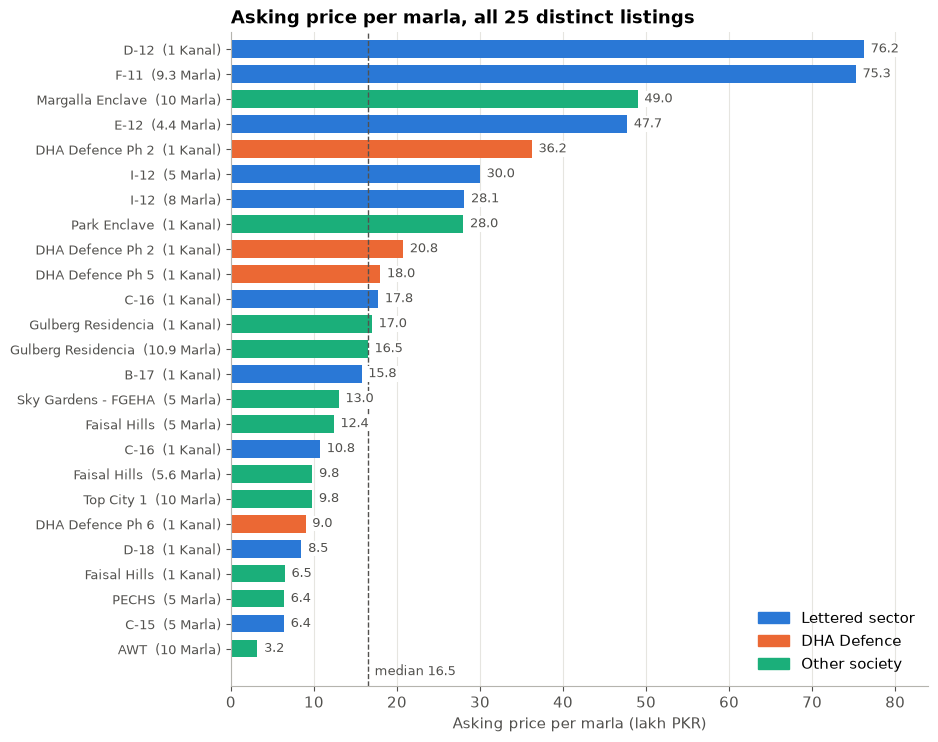

In [15]:
d = clean.sort_values('price_per_marla_lakh')
labels = d['locality'] + np.where(d['dha_phase'].notna(), ' Ph ' + d['dha_phase'].fillna(''), '') + '  (' + d['area_text'] + ')'

fig, ax = plt.subplots(figsize=(9, 8.5))
ax.barh(range(len(d)), d['price_per_marla_lakh'], color=d['location_group'].map(group_colors), height=0.7)
ax.set_yticks(range(len(d)))
ax.set_yticklabels(labels, fontsize=9.5)
for i, v in enumerate(d['price_per_marla_lakh']):
    ax.text(v + 0.8, i, f'{v:.1f}', va='center', fontsize=9, color='#52514e', bbox=dict(facecolor='white', edgecolor='none', pad=1), zorder=3)
ax.axvline(d['price_per_marla_lakh'].median(), color='#52514e', lw=1, ls='--', zorder=1)
ax.text(d['price_per_marla_lakh'].median() + 0.8, -0.9, f"median {d['price_per_marla_lakh'].median():.1f}", fontsize=9, color='#52514e', va='center')
ax.set_ylim(-1.5, len(d) - 0.3)
ax.set_xlabel('Asking price per marla (lakh PKR)')
ax.set_title('Asking price per marla, all 25 distinct listings')
ax.grid(axis='x')
ax.set_xlim(0, 84)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
ax.legend(handles, group_colors.keys(), loc='lower right', frameon=False)
fig.savefig('charts/01_price_per_marla_by_listing.png')
plt.show()

Each bar is a single listing, not a location average. D-12 and F-11 are in a class of their own, then Margalla Enclave and E-12 just under 50. Lettered sectors are at both ends: C-15, D-18 and one of the C-16 plots sit in the bottom third, so the label alone says little.

In [16]:
by_group = clean.groupby('location_group')['price_per_marla_lakh'].agg(['count', 'median', 'mean', 'min', 'max']).round(2)
by_group.sort_values('median', ascending=False)

,count,median,mean,min,max
location_group,,,,,
Lettered sector,10,22.94,31.65,6.4,76.25
DHA Defence,4,19.38,21.00,9.0,36.25
Other society,11,12.40,15.60,3.2,49.00


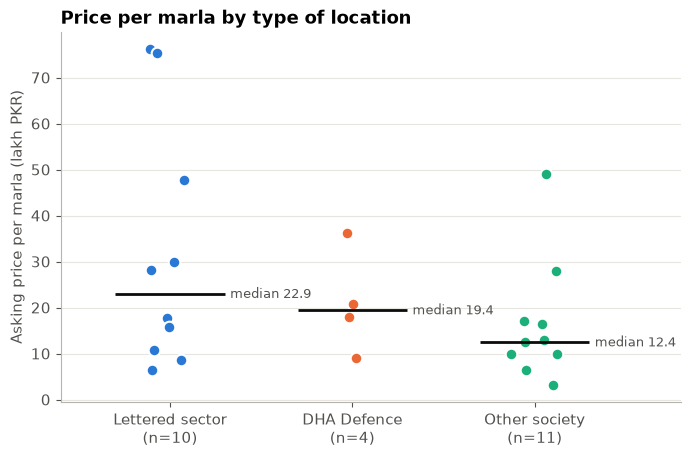

In [17]:
order = by_group.sort_values('median', ascending=False).index.tolist()
rng = np.random.default_rng(3)

fig, ax = plt.subplots(figsize=(8, 4.8))
for i, g in enumerate(order):
    vals = clean.loc[clean['location_group'] == g, 'price_per_marla_lakh']
    ax.scatter(i + rng.uniform(-0.13, 0.13, len(vals)), vals, s=70, color=group_colors[g], edgecolor='white', linewidth=1.5, zorder=3)
    ax.hlines(vals.median(), i - 0.3, i + 0.3, color='#0b0b0b', lw=2, zorder=4)
    ax.text(i + 0.33, vals.median(), f'median {vals.median():.1f}', va='center', fontsize=9.5, color='#52514e')
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f'{g}\n(n={by_group.loc[g, "count"]})' for g in order])
ax.set_xlim(-0.6, len(order) - 0.2)
ax.set_ylabel('Asking price per marla (lakh PKR)')
ax.set_title('Price per marla by type of location')
ax.grid(axis='y')
fig.savefig('charts/02_price_per_marla_by_location_group.png')
plt.show()

The lettered sectors have the highest median but also by far the widest range. DHA is tighter apart from one high corner plot in Phase 2. The other societies are the cheapest group. Groups of 4 to 11 listings, so this is a description of the sample and nothing more.

### By locality, with a minimum count

Normally I would want at least 10 or so listings before ranking a location. Here no locality has more than 4, and 12 of the 17 have exactly one. The best I can do is show the localities with at least 2 listings and be clear it is indicative only.

In [18]:
MIN_LISTINGS = 2
by_loc = clean.groupby('locality').agg(listings=('listing_id', 'count'),
                                       median_ppm=('price_per_marla_lakh', 'median'),
                                       min_ppm=('price_per_marla_lakh', 'min'),
                                       max_ppm=('price_per_marla_lakh', 'max'),
                                       group=('location_group', 'first'))
print('localities with a single listing:', (by_loc['listings'] == 1).sum(), 'of', len(by_loc))
ranked = by_loc[by_loc['listings'] >= MIN_LISTINGS].sort_values('median_ppm', ascending=False).round(2)
ranked

localities with a single listing: 12 of 17


,listings,median_ppm,min_ppm,max_ppm,group
locality,,,,,
I-12,2,29.06,28.12,30.00,Lettered sector
DHA Defence,4,19.38,9.00,36.25,DHA Defence
Gulberg Residencia,2,16.76,16.51,17.00,Other society
C-16,2,14.25,10.75,17.75,Lettered sector
Faisal Hills,3,9.82,6.50,12.40,Other society


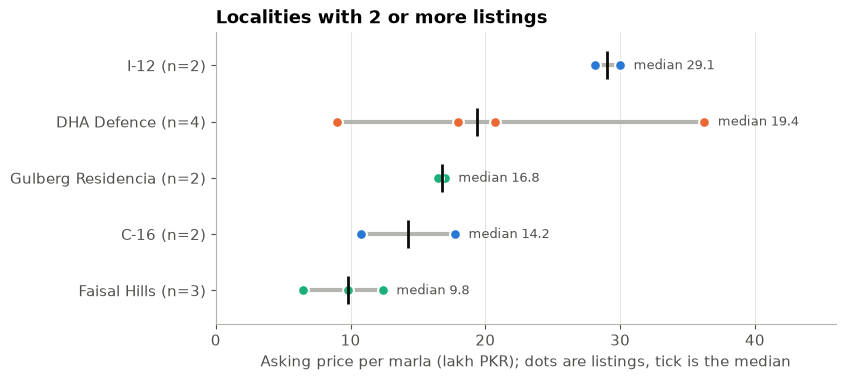

In [19]:
r = ranked.sort_values('median_ppm')
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (loc, row) in enumerate(r.iterrows()):
    ax.hlines(i, row['min_ppm'], row['max_ppm'], color='#b5b4ae', lw=3, zorder=2)
    pts = clean.loc[clean['locality'] == loc, 'price_per_marla_lakh']
    ax.scatter(pts, [i] * len(pts), s=60, color=group_colors[row['group']], edgecolor='white', linewidth=1.5, zorder=3)
    ax.scatter(row['median_ppm'], i, marker='|', s=420, color='#0b0b0b', linewidth=2, zorder=4)
    ax.text(row['max_ppm'] + 1, i, f"median {row['median_ppm']:.1f}", va='center', fontsize=9.5, color='#52514e')
ax.set_yticks(range(len(r)))
ax.set_yticklabels([f'{loc} (n={n})' for loc, n in zip(r.index, r['listings'])])
ax.set_ylim(-0.6, len(r) - 0.4)
ax.set_xlim(0, 46)
ax.set_xlabel('Asking price per marla (lakh PKR); dots are listings, tick is the median')
ax.set_title('Localities with 2 or more listings')
ax.grid(axis='x')
fig.savefig('charts/03_localities_with_2plus_listings.png')
plt.show()

Even within one locality the listings disagree a lot: the four DHA plots go from 9 to about 36 lakh per marla, and the two C-16 kanal plots are 10.75 and 17.75.

In [20]:
dha = clean[clean['locality'] == 'DHA Defence'].sort_values('price_per_marla_lakh', ascending=False)
dha[['title', 'dha_phase', 'price_text', 'area_text', 'price_per_marla_lakh', 'is_corner']]

,title,dha_phase,price_text,area_text,price_per_marla_lakh,is_corner
4,DHA Phase 2 Sector A | Prime Boulevard Corner Plot | Double Catego...,2,7.25 Crore,1 Kanal,36.25,True
8,"1 Kanal Beautiful Front Garden Plot For Sale DHA Phase 2, Sector D...",2,4.15 Crore,1 Kanal,20.75,False
9,"1 Kanal Plot For Sale Sector C, DHA Phase 5, Islamabad",5,3.6 Crore,1 Kanal,18.00,False
19,Ivestor'S Deal Plot For Sale DHA Phase 6 Islamabad (Sector A-2),6,1.8 Crore,1 Kanal,9.00,False


All four DHA listings are 1 kanal, so the gap is not a size effect. The Phase 2 boulevard corner plot asks 7.25 crore, the Phase 6 one 1.8 crore. Two listings for Phase 2 and one each for Phases 5 and 6 is not enough to say anything about phases in general.

### Plot size

In [21]:
by_size = clean.groupby('size_class', observed=True).agg(listings=('listing_id', 'count'),
                                                         median_price_crore=('price_crore', 'median'),
                                                         median_ppm=('price_per_marla_lakh', 'median'),
                                                         min_ppm=('price_per_marla_lakh', 'min'),
                                                         max_ppm=('price_per_marla_lakh', 'max')).round(2)
print(by_size)
print()
print('spearman, area vs total price: %.2f' % clean['area_marla'].corr(clean['price_pkr'], method='spearman'))
print('spearman, area vs price per marla: %.2f' % clean['area_marla'].corr(clean['price_per_marla_lakh'], method='spearman'))

               listings  median_price_crore  median_ppm  min_ppm  max_ppm
size_class                                                               
about 5 marla         7                0.62       12.40      6.4    47.73
8-11 marla            6                2.02       22.32      3.2    75.27
1 kanal              12                3.47       17.38      6.5    76.25



spearman, area vs total price: 0.58
spearman, area vs price per marla: 0.06


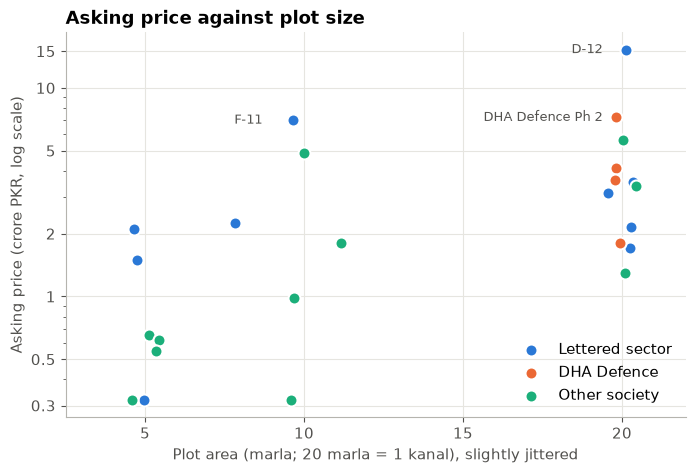

In [22]:
jit = np.random.default_rng(7)
fig, ax = plt.subplots(figsize=(8, 5))
for g, c in group_colors.items():
    s = clean[clean['location_group'] == g]
    # a little sideways jitter so plots of the same size and price do not hide each other
    ax.scatter(s['area_marla'] + jit.uniform(-0.45, 0.45, len(s)), s['price_crore'], s=75, color=c, edgecolor='white', linewidth=1.5, label=g, zorder=3)
for _, row in clean.nlargest(3, 'price_crore').iterrows():
    lab = row['locality'] + (' Ph ' + row['dha_phase'] if pd.notna(row['dha_phase']) else '')
    ax.annotate(lab, (row['area_marla'], row['price_crore']), xytext=(-14, 0), textcoords='offset points', ha='right', va='center', fontsize=9.5, color='#52514e')
ax.set_yscale('log')
ax.set_yticks([0.3, 0.5, 1, 2, 5, 10, 15])
ax.set_yticklabels(['0.3', '0.5', '1', '2', '5', '10', '15'])
ax.set_xticks([5, 10, 15, 20])
ax.set_xlim(2.5, 22)
ax.set_xlabel('Plot area (marla; 20 marla = 1 kanal), slightly jittered')
ax.set_ylabel('Asking price (crore PKR, log scale)')
ax.set_title('Asking price against plot size')
ax.grid(True)
ax.legend(frameon=False, loc='lower right')
fig.savefig('charts/04_price_vs_area.png')
plt.show()

Bigger plots cost more in total, as expected, but size explains little: 1 kanal plots range from 1.3 crore to 15.25 crore, and price per marla has essentially no rank relationship with size here. Where the plot is matters far more than how big it is, at least in these 25.

In [23]:
corner = clean.groupby('is_corner')['price_per_marla_lakh'].agg(['count', 'median', 'min', 'max']).round(2)
corner

,count,median,min,max
is_corner,,,,
False,21,13.00,3.20,75.27
True,4,41.99,15.75,76.25


Four titles mention a corner plot and their median is higher, but three of the four are in places that are expensive anyway (D-12, E-12 and the DHA Phase 2 boulevard), so I would not read a corner premium into this.

## Highest / lowest / most

In [24]:
def show(label, row, extra=''):
    print(f"{label}: {row['locality']} - {row['price_text']} for {row['area_text']} ({row['price_per_marla_lakh']:.2f} lakh per marla){extra}")

show('Highest total asking price', clean.loc[clean['price_pkr'].idxmax()])
low = clean[clean['price_pkr'] == clean['price_pkr'].min()]
print(f"Lowest total asking price: {low['price_text'].iloc[0]}, shared by {len(low)} listings ({', '.join(low['locality'])})")
show('Highest price per marla', clean.loc[clean['price_per_marla_lakh'].idxmax()])
show('Second highest price per marla', clean.sort_values('price_per_marla_lakh', ascending=False).iloc[1])
show('Lowest price per marla', clean.loc[clean['price_per_marla_lakh'].idxmin()])
k = clean[clean['area_marla'] == 20]
show('Most expensive 1 kanal plot', k.loc[k['price_pkr'].idxmax()])
show('Cheapest 1 kanal plot', k.loc[k['price_pkr'].idxmin()])
print(f"Ratio between those two kanal plots: {k['price_pkr'].max() / k['price_pkr'].min():.1f}x")
show('Smallest plot', clean.loc[clean['area_marla'].idxmin()])
print(f"Most common plot size: 1 kanal, {len(k)} of {len(clean)} listings; then 5 marla, {(clean['area_marla'] == 5).sum()}")
print(f"Locality with most listings: {by_loc['listings'].idxmax()} ({by_loc['listings'].max()}), then Faisal Hills ({by_loc.loc['Faisal Hills', 'listings']})")
print(f"Localities: {len(by_loc)}, of which {(by_loc['listings'] == 1).sum()} have one listing")
print(f"Median asking price: {clean['price_crore'].median():.2f} crore; median price per marla: {clean['price_per_marla_lakh'].median():.2f} lakh")
print(f"Listings at 1 crore or more: {(clean['price_crore'] >= 1).sum()} of {len(clean)}")
print(f"Total asking value of the 25 listings: {clean['price_crore'].sum():.2f} crore")
print(f"Raw rows that were repeats: {len(raw) - len(clean):,} of {len(raw):,} ({(len(raw) - len(clean)) / len(raw):.2%})")

Highest total asking price: D-12 - 15.25 Crore for 1 Kanal (76.25 lakh per marla)
Lowest total asking price: 32 Lakh, shared by 3 listings (C-15, PECHS, AWT)
Highest price per marla: D-12 - 15.25 Crore for 1 Kanal (76.25 lakh per marla)
Second highest price per marla: F-11 - 7 Crore for 9.3 Marla (75.27 lakh per marla)
Lowest price per marla: AWT - 32 Lakh for 10 Marla (3.20 lakh per marla)
Most expensive 1 kanal plot: D-12 - 15.25 Crore for 1 Kanal (76.25 lakh per marla)
Cheapest 1 kanal plot: Faisal Hills - 1.3 Crore for 1 Kanal (6.50 lakh per marla)
Ratio between those two kanal plots: 11.7x
Smallest plot: E-12 - 2.1 Crore for 4.4 Marla (47.73 lakh per marla)
Most common plot size: 1 kanal, 12 of 25 listings; then 5 marla, 5
Locality with most listings: DHA Defence (4), then Faisal Hills (3)
Localities: 17, of which 12 have one listing
Median asking price: 2.10 crore; median price per marla: 16.51 lakh
Listings at 1 crore or more: 18 of 25
Total asking value of the 25 listings: 76.2

## What the 25 listings show

- The file has 18,700 rows but only 25 distinct listings, each repeated once for every one of 748 scraped pages. 99.87% of rows are repeats.
- Across the 25, asking price per marla runs from 3.2 lakh (AWT) to 76.25 lakh (D-12), roughly a 24x spread. Median is 16.51 lakh, mean 22.89 lakh.
- The two most expensive per marla are D-12 (76.25) and F-11 (75.27), both far above the rest; next are Margalla Enclave at 49.00 and E-12 at 47.73.
- Lettered sectors have the highest median per marla (22.94 lakh, n=10), then DHA Defence (19.38, n=4), then other societies (12.40, n=11). The sector group is very wide (6.4 to 76.25).
- The four DHA Defence plots are all 1 kanal and still range from 1.8 crore (Phase 6) to 7.25 crore (Phase 2 corner).
- Plot size says little about price per marla (Spearman 0.06 with area; 0.58 for total price). 1 kanal plots alone range from 1.3 crore (Faisal Hills) to 15.25 crore (D-12), an 11.7x gap.
- Only 5 of 17 localities have 2 or more listings, and none has more than 4, so no proper location ranking is possible.

## Limitations

- 25 listings. Nothing here generalises to the Islamabad market.
- Asking prices from listings, not transaction prices.
- No dates in the file, so when it was scraped is unknown and there are no trends.
- The 25 are whatever was on the first results page, presumably including promoted listings, so not a random sample either. That is a guess about why these 25; the file does not say.
- A few listings are not like-for-like (a pair of plots listed as 1 kanal, a plot file, a commercial plot, one mentioning instalments, one titled as a residence). They are flagged, not removed.
- No information on plot features beyond the title: development status, possession, road width, exact block.
- Marla taken as 225 sq ft (1 kanal = 20 marla), which fits the six titles that give dimensions (five exactly, one rounded).